## REINFORCE with Baseline – Stage 2 최종 모델 (Seed 42)
**실험 조건:**

메뉴 종류: 2개 (치즈, 페퍼로니)

재료 종류: 3개 (도우, 치즈, 페퍼로니)

최대 주문 대기 수: 4개

행동 종류: 5개

주문 타이머: 16~24스텝

주문 처리 방식: 전체 메뉴 기준 FIFO

정답 서빙 보상: +150

타임아웃 페널티: -50

잘못된 서빙 페널티: -15

잘못된 재료 조작 페널티: -2

행동당 페널티: -0.1

학습 에피소드: 2,000

할인율(γ): 0.99

학습률(Learning Rate): 0.001 (Policy, Value Network)

Optimizer: Adam

학습 시드(Seed): 42

Episode [50/2000] | Total Reward: -275.40 | Avg Reward (50): -203.90 | Success: 0 | Timeout: 4 | Value Loss: 35671.4648
Episode [100/2000] | Total Reward: 169.70 | Avg Reward (50): -154.69 | Success: 2 | Timeout: 2 | Value Loss: 28429.4258
Episode [150/2000] | Total Reward: -75.40 | Avg Reward (50): -134.83 | Success: 1 | Timeout: 3 | Value Loss: 8090.4927
Episode [200/2000] | Total Reward: 119.90 | Avg Reward (50): -141.71 | Success: 2 | Timeout: 2 | Value Loss: 30380.9785
Episode [250/2000] | Total Reward: -50.00 | Avg Reward (50): -113.80 | Success: 1 | Timeout: 3 | Value Loss: 6049.1875
Episode [300/2000] | Total Reward: 385.80 | Avg Reward (50): -70.88 | Success: 3 | Timeout: 1 | Value Loss: 89130.0703
Episode [350/2000] | Total Reward: -48.40 | Avg Reward (50): -65.02 | Success: 1 | Timeout: 3 | Value Loss: 4907.9575
Episode [400/2000] | Total Reward: 377.70 | Avg Reward (50): 32.93 | Success: 3 | Timeout: 1 | Value Loss: 83998.7734
Episode [450/2000] | Total Reward: 134.80 | Avg

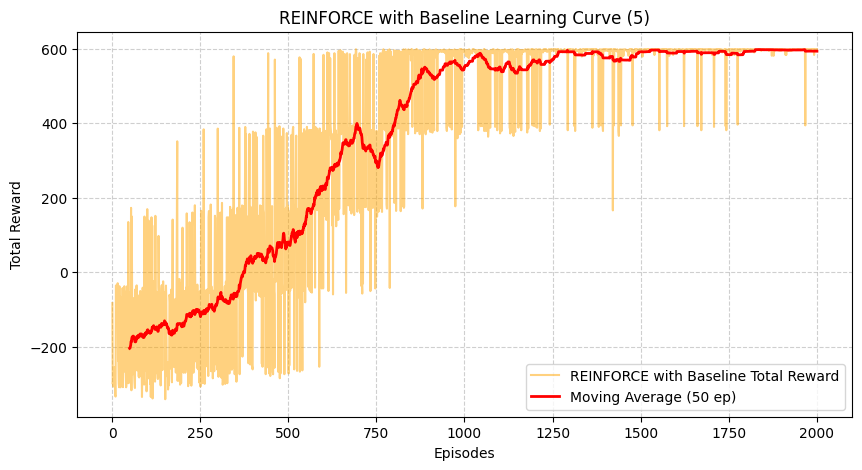

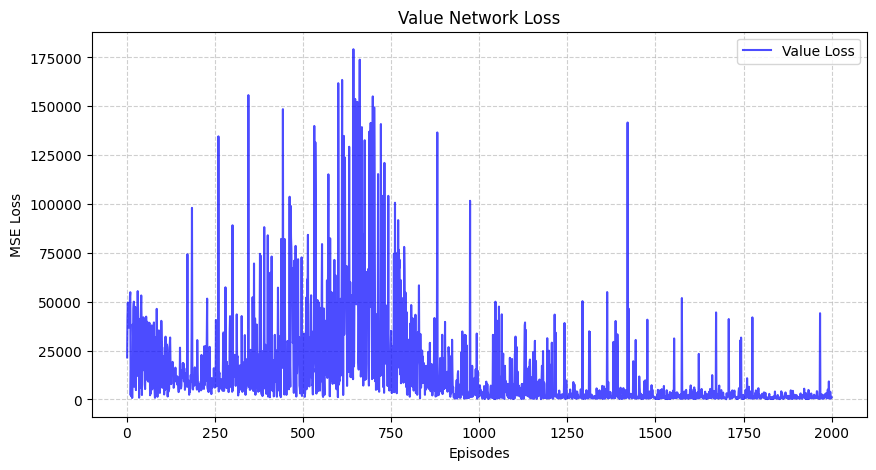

=== All 2000 Episodes ===
Idle           :   1952 (5.47%)
Add Dough      :  10656 (29.84%)
Add Cheese     :  10348 (28.98%)
Add Pepperoni  :   5379 (15.06%)
Serve          :   7378 (20.66%)

=== Last 100 Episodes ===
Idle           :      3 (0.21%)
Add Dough      :    422 (29.04%)
Add Cheese     :    405 (27.87%)
Add Pepperoni  :    221 (15.21%)
Serve          :    402 (27.67%)

=== Last 100 Episodes Performance ===
Average Reward: 595.24
Successful Orders: 399
Timed-out Orders: 1
Success Rate: 99.75%
Timeout Rate: 0.25%


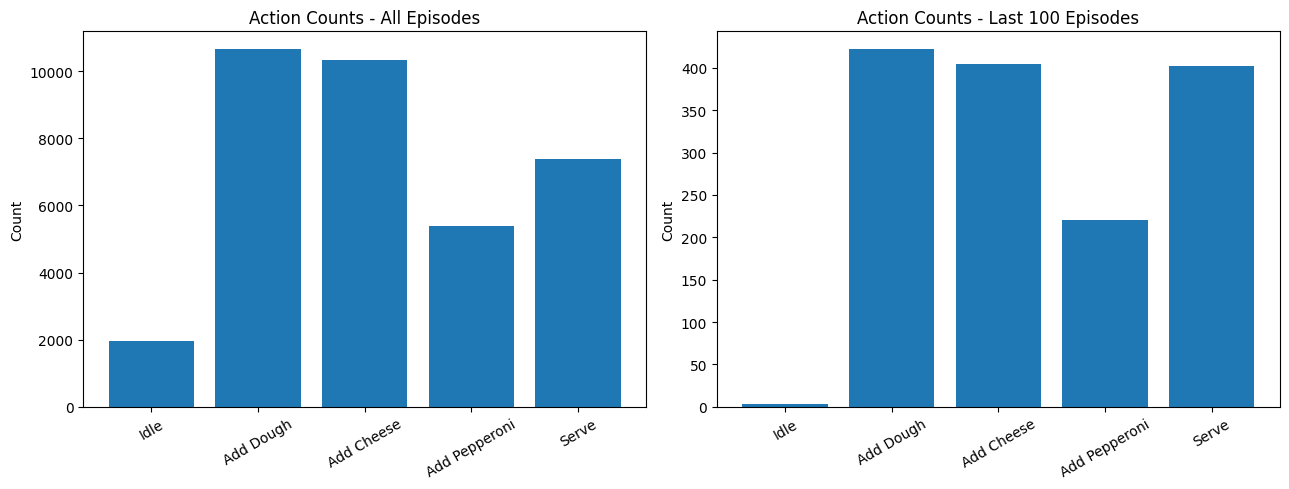

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 1. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4 # ⭐ 최대 주문 대기 수 4로 확장

        # [d, c, p, m1, t1, m2, t2, m3, t3, m4, t4] = 11 dim
        # d, c, p: 0 or 1
        # m1, m2, m3, m4: 0 (No order), 1 (Cheese), 2 (Pepperoni)
        # t1, t2, t3, t4: 0 to 24 (Normalized by 24.0)
        # Menu IDs can reach 2, so the upper bound is not 1 for all dimensions.
        self.observation_space = spaces.Box(
            low=0.0,
            high=np.array(
                [1, 1, 1, 2, 1, 2, 1, 2, 1, 2, 1],
                dtype=np.float32
            ),
            shape=(11,),
            dtype=np.float32
        )

        self.action_space = spaces.Discrete(5)
        # 0: Idle, 1: Add Dough, 2: Add Cheese,
        # 3: Add Pepperoni, 4: Serve

        self.menus = {
            1: [1.0, 1.0, 0.0],  # Cheese Pizza
            2: [1.0, 1.0, 1.0]   # Pepperoni Pizza
        }

        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(3, dtype=np.float32)
        self.orders = []

        for _ in range(self.max_orders):
            self._add_order()

        self.steps = 0
        self.terminated_count = 0
        return self._get_obs(), {}

    def _add_order(self):
        if len(self.orders) < self.max_orders:
            menu_id = int(self.np_random.choice([1, 2]))
            timer = int(self.np_random.integers(16, 25)) # ⭐ 주문 타이머 8~12 → 16~24스텝 확장
            self.orders.append({
                'menu_id': menu_id,
                'timer': timer
            })

    def _get_obs(self):
        obs = list(self.counter)

        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.append(float(self.orders[i]['menu_id']))
                obs.append(float(self.orders[i]['timer']) / 24.0) # ⭐ 타이머 최댓값 24 기준 정규화 (기존 12 → 24)
            else:
                obs.append(0.0)
                obs.append(0.0)

        return np.array(obs, dtype=np.float32)

    def step(self, action):
        self.steps += 1
        reward = -0.1
        terminated = False
        truncated = self.steps >= 100

        # 1. Action Processing & Rule Checking
        if action == 1:  # Add Dough
            if self.counter[0] == 1.0:
                reward -= 2.0
            else:
                self.counter[0] = 1.0

        elif action == 2:  # Add Cheese
            if self.counter[1] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0:
                reward -= 2.0
            else:
                self.counter[1] = 1.0

        elif action == 3:  # Add Pepperoni
            if self.counter[2] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[2] = 1.0

        elif action == 4:  # Serve
            if len(self.orders) > 0:
                target_menu = self.orders[0]['menu_id']
                target_recipe = self.menus[target_menu]

                if np.array_equal(self.counter, target_recipe):
                    reward += 150.0  # ⭐ 정확한 피자 서빙 보상 (+150)
                    self.orders.pop(0)
                    self.counter = np.zeros(3, dtype=np.float32)
                else:
                    reward -= 15.0
                    self.counter = np.zeros(3, dtype=np.float32)
            else:
                reward -= 1.0

        # 2. Timer Update & Timeout Check
        orders_to_remove = []

        for order in self.orders:
            order['timer'] -= 1.0
            if order['timer'] <= 0:
                reward -= 50.0 # ⭐ Timeout penalty (-10 -> -50)
                orders_to_remove.append(order)

        for expired in orders_to_remove:
            if expired in self.orders:
                self.orders.remove(expired)

        if len(self.orders) == 0:
            terminated = True

        return self._get_obs(), reward, terminated, truncated, {}


# 2. Define Policy Network (same as original REINFORCE)
class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, action_dim)

        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x


# 3. Define Value Network (NEW: Baseline)
class ValueNetwork(nn.Module):
    def __init__(self, state_dim):
        super(ValueNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x



# 4. REINFORCE with Baseline Training Function
# + Action Count & Success/Timeout Tracking

def train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
):
    reward_history = []
    policy_loss_history = []
    value_loss_history = []

    # Tracking
    action_history = []
    success_history = []
    timeout_history = []

    for episode in range(num_episodes):
        state, _ = env.reset()

        log_probs = []
        states = []
        rewards = []

        # Count each action in this episode
        action_counts = np.zeros(5, dtype=np.int32)

        # Track orders completed / expired
        success_count = 0
        timeout_count = 0

        done = False

        while not done:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)

            probs = policy_net(state_tensor)
            m = torch.distributions.Categorical(probs)
            action = m.sample()

            action_id = action.item()

            # Record action
            action_counts[action_id] += 1

            log_probs.append(m.log_prob(action))
            states.append(state_tensor.squeeze(0))

            # Count orders before step
            orders_before = len(env.orders)
            first_order_before = (
                env.orders[0]['menu_id']
                if orders_before > 0 else None
            )
            counter_before = env.counter.copy()

            next_state, reward, terminated, truncated, info = env.step(
                action_id
            )

            # Detect successful serve
            if action_id == 4 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    success_count += 1

            # Infer expired orders from order count
            orders_after = len(env.orders)
            removed_orders = orders_before - orders_after

            if action_id == 4 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    removed_orders -= 1

            timeout_count += max(0, removed_orders)

            done = terminated or truncated
            rewards.append(reward)
            state = next_state

        total_reward = sum(rewards)

        reward_history.append(total_reward)
        action_history.append(action_counts)
        success_history.append(success_count)
        timeout_history.append(timeout_count)

        # Monte Carlo Returns
        returns = []
        G = 0.0

        for r in reversed(rewards):
            G = r + gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)

        # Value Network
        states_tensor = torch.stack(states)
        values = value_net(states_tensor).squeeze(-1)

        # Advantage
        advantages = returns - values.detach()

        # Policy Loss
        log_probs_tensor = torch.stack(log_probs).view(-1)
        policy_loss = -(log_probs_tensor * advantages).sum()

        # Value Loss
        value_loss = nn.functional.mse_loss(values, returns)

        policy_optimizer.zero_grad()
        policy_loss.backward()
        policy_optimizer.step()

        value_optimizer.zero_grad()
        value_loss.backward()
        value_optimizer.step()

        policy_loss_history.append(policy_loss.item())
        value_loss_history.append(value_loss.item())

        if (episode + 1) % 50 == 0:
            avg_reward = np.mean(reward_history[-50:])

            print(
                    f"Episode [{episode+1}/{num_episodes}] | "
                    f"Total Reward: {total_reward:.2f} | "
                    f"Avg Reward (50): {avg_reward:.2f} | "
                    f"Success: {success_count} | "
                    f"Timeout: {timeout_count} | "
                    f"Value Loss: {value_loss.item():.4f}"
        )

    return (
        reward_history,
        policy_loss_history,
        value_loss_history,
        np.array(action_history),
        np.array(success_history),
        np.array(timeout_history)
    )



# 5. Execution

torch.manual_seed(42)

env = PizzaShopEnv()
env.reset(seed=42)

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy_net = PolicyNetwork(state_dim, action_dim)
value_net = ValueNetwork(state_dim)

policy_optimizer = optim.Adam(policy_net.parameters(), lr=0.001)
value_optimizer = optim.Adam(value_net.parameters(), lr=0.001)

(
    rewards_history,
    policy_losses,
    value_losses,
    action_history,
    success_history,
    timeout_history
) = train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
)


# 6. Visualization: Total Reward
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(rewards_history) + 1),
    rewards_history,
    label='REINFORCE with Baseline Total Reward',
    color='orange',
    alpha=0.5
    )

window_size = 50

if len(rewards_history) >= window_size:
    moving_avg = np.convolve(
        rewards_history,
        np.ones(window_size) / window_size,
        mode='valid'
    )

    plt.plot(
        range(window_size, len(rewards_history) + 1),
        moving_avg,
        label=f'Moving Average ({window_size} ep)',
        color='red',
        linewidth=2
    )

plt.title('REINFORCE with Baseline Learning Curve (5)')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 7. Visualization: Value Loss
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(value_losses) + 1),
    value_losses,
    label='Value Loss',
    color='blue',
    alpha=0.7
    )

plt.title('Value Network Loss')
plt.xlabel('Episodes')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 8. Action Selection Analysis

action_names = [
    'Idle',
    'Add Dough',
    'Add Cheese',
    'Add Pepperoni',
    'Serve'
]

total_counts = action_history.sum(axis=0)
last_100_counts = action_history[-100:].sum(axis=0)

total_steps = total_counts.sum()
last_100_steps = last_100_counts.sum()

print("=== All 2000 Episodes ===")
for name, count in zip(action_names, total_counts):
    percentage = 100 * count / max(total_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes ===")
for name, count in zip(action_names, last_100_counts):
    percentage = 100 * count / max(last_100_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes Performance ===")
print(f"Average Reward: {np.mean(rewards_history[-100:]):.2f}")
print(f"Successful Orders: {success_history[-100:].sum()}")
print(f"Timed-out Orders: {timeout_history[-100:].sum()}")

total_orders = (
    success_history[-100:].sum()
    + timeout_history[-100:].sum()
)

if total_orders > 0:
    print(
        f"Success Rate: "
        f"{100 * success_history[-100:].sum() / total_orders:.2f}%"
    )
    print(
        f"Timeout Rate: "
        f"{100 * timeout_history[-100:].sum() / total_orders:.2f}%"
    )

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(action_names, total_counts)
axes[0].set_title('Action Counts - All Episodes')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(action_names, last_100_counts)
axes[1].set_title('Action Counts - Last 100 Episodes')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

세부 실험 과정 및 결과 분석은 02_1_reinforce_with_baseline.ipynb 참고.